## MUSIC POPULARITY PROJECT

### Group 6

### Project Overview
This project is carried out by the data team at a music streaming service. The A&R (Artists & Repertoire) department wants to use data to make better decisions about which music to back, so we analyse Spotify track data to answer three questions.

### Objectives
1. **What makes a track popular?** (Regression): identify which audio features and track characteristics best explain a song's popularity score.
2. **Can we spot a hit before it charts?** (Classification): build a model that predicts whether a track is likely to be a hit, using only information available before release.
3. **What moods exist inside a genre?** (Clustering): group tracks within our chosen genre into distinct mood profiles based on their audio features.

### Dataset
- **Source:** Kaggle
- **File:** `spotify_tracks.csv`

### Team

## Part 1 — Load the data

### Load the Data

#### 1.1 Imports

In [65]:
# Import of libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

#### 1.2 Select the genre for the team

In [66]:
# Select the genre
GENRE = 'acoustic'      

RANDOM_STATE = 42   

print(f'Working on: {GENRE}')

Working on: acoustic


#### 1.3 Read the file and select the dataset

In [67]:
df = pd.read_csv('spotify_tracks.csv')

print('Rows:', df.shape[0])
print('Columns:', df.shape[1])
df.head()


Rows: 114000
Columns: 21


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


#### 1.4 Review the dataset structure and summary

### Review Structure and Summary

In [68]:
# Print first few rows
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [69]:
# Check the shape of the dataframe(number of rows and columns)
df.shape

(114000, 21)

In [70]:
# Check the data types of each column
df.dtypes

Unnamed: 0            int64
track_id                str
artists                 str
album_name              str
track_name              str
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre             str
dtype: object

In [71]:
# Check for the data information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [72]:
# Summary statistics of the numerical columns
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [73]:
# Checking for missing values in the dataset

missing_values = df.isnull().sum()
print(missing_values)

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


In [74]:
# Check for duplicates in the dataset
duplicates = df.duplicated().sum()
print(f'Number of duplicate rows: {duplicates}')

Number of duplicate rows: 0


#### 1.5 Check whether the selected genre exists in the data

In [75]:
# Check if genre exits in the dataset
# Does the chosen genre exist?
if GENRE in df['track_genre'].unique():
    print(f'The genre "{GENRE}" exists in the dataset.')

The genre "acoustic" exists in the dataset.


#### 1.6 Filter the dataset to the chosen genre

In [76]:
# Filter the dataset for the selected genre
df_acoustic = df[df['track_genre'] == GENRE]

df_acoustic

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.03220,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.92400,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.21000,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.90500,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.46900,0.000000,0.0829,0.167,119.949,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,995,1epXnhFfFToKeugQWBCsQg,Harley Poe,Wretched. Filthy. Ugly.,Maria,26,196226,True,0.633,0.8320,0,-6.840,1,0.0863,0.02740,0.000008,0.0957,0.838,130.912,4,acoustic
996,996,5aBpIqXfktr9SSwyAi8Hlj,Taj Mahal,The Essential Taj Mahal,"Corinna - From ""The Natch'l Blues""",29,180920,False,0.621,0.2940,9,-13.468,1,0.1100,0.55800,0.000025,0.0946,0.728,78.599,4,acoustic
997,997,1ZD2MlKRTYKI8oewOt28mc,Pigeon Pit,Treehouse,Tall Cans,26,186461,True,0.648,0.3890,4,-8.275,1,0.0927,0.80700,0.000098,0.1100,0.378,86.360,4,acoustic
998,998,3zVMv0mxjnJRw2BX5ryCqT,Chuck Ragan,Covering Ground,You Get What You Give,26,217293,False,0.303,0.5060,9,-6.890,1,0.0325,0.49600,0.000000,0.1780,0.412,161.463,3,acoustic


#### Write: Three observations about the filtered dataset

In [77]:
# Observations: (1)
df_acoustic.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1000 non-null   int64  
 1   track_id          1000 non-null   str    
 2   artists           1000 non-null   str    
 3   album_name        1000 non-null   str    
 4   track_name        1000 non-null   str    
 5   popularity        1000 non-null   int64  
 6   duration_ms       1000 non-null   int64  
 7   explicit          1000 non-null   bool   
 8   danceability      1000 non-null   float64
 9   energy            1000 non-null   float64
 10  key               1000 non-null   int64  
 11  loudness          1000 non-null   float64
 12  mode              1000 non-null   int64  
 13  speechiness       1000 non-null   float64
 14  acousticness      1000 non-null   float64
 15  instrumentalness  1000 non-null   float64
 16  liveness          1000 non-null   float64
 17  valence

##### 1. Based on the information above, We can see that the dataset has 1000 rows and 21 columns.The columns include various features related to the tracks, such as 'track_name', 'track_artist', 'track_genre', 'track_popularity', and several audio features like 'danceability', 'energy', 'loudness', etc. There are no missing values in the dataset.

In [78]:
# Observations: (2) and (3)
df_acoustic.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,42.483000,214896.957000,0.549593,0.435368,5.045000,-9.447843,0.816000,0.043247,0.566816,0.038336,0.153244,0.424023,119.010624,3.885000
std,288.819436,16.541019,55615.279398,0.122203,0.236318,3.588294,3.773481,0.387678,0.025636,0.330443,0.159383,0.105335,0.222394,29.771694,0.426564
min,0.000000,0.000000,59823.000000,0.213000,0.011900,0.000000,-28.276000,0.000000,0.023200,0.000006,0.000000,0.028400,0.041900,53.845000,1.000000
25%,249.750000,29.000000,178664.250000,0.463000,0.254000,2.000000,-11.466000,1.000000,0.030500,0.262250,0.000000,0.100000,0.247750,94.999000,4.000000
50%,499.500000,47.000000,214822.000000,0.558500,0.394500,5.000000,-9.003000,1.000000,0.035200,0.691500,0.000003,0.114500,0.374000,117.751500,4.000000
75%,749.250000,54.000000,246286.500000,0.639000,0.624000,8.000000,-6.637250,1.000000,0.045925,0.861000,0.000213,0.159000,0.569500,139.696750,4.000000
max,999.000000,82.000000,578064.000000,0.879000,0.974000,11.000000,-1.963000,1.000000,0.403000,0.992000,0.978000,0.944000,0.975000,204.961000,5.000000


#### 2. Acoustic tracks are generally quite acoustic: acousticness mean = 0.567, median = 0.692, 75th percentile = 0.861, max = 0.992, This suggests most tracks in this subset are strongly acoustic, not just lightly acoustic

#### 3. They are moderately popular, but not highly popular:            popularity mean = 42.48, median = 47, range = 0 to 82, spread is fairly wide (std ≈ 16.54), Meaning acoustic tracks in this sample are not usually super viral, but they can still reach decent popularity.

## Part 2 ? Clean the data

### 2.1 Remove the unnecessary index column

In [79]:
# Start with only the selected genre, not the full dataset.
df_acoustic = df_acoustic.copy()

# Remove the extra row-number column if it is present.
if 'Unnamed: 0' in df_acoustic.columns:
    df_acoustic = df_acoustic.drop(columns=['Unnamed: 0'])

print('Acoustic tracks:', len(df_acoustic))
print('Unused index column removed:', 'Unnamed: 0' not in df_acoustic.columns)

Acoustic tracks: 1000
Unused index column removed: True


### 2.2 Check for duplicate tracks

In [80]:
# Check repeated Spotify track IDs within the acoustic genre.
duplicate_count = df_acoustic.duplicated(subset='track_id').sum()
print('Duplicate tracks:', duplicate_count)

# Keep only one copy if any repeated IDs are found.
df_acoustic = df_acoustic.drop_duplicates(subset='track_id').copy()
print('Tracks after duplicate check:', len(df_acoustic))

Duplicate tracks: 0
Tracks after duplicate check: 1000


### 2.3 Handle missing values in the dataset

In [81]:
# Count missing values before cleaning.
missing_before = int(df_acoustic.isna().sum().sum())
rows_before = len(df_acoustic)
print('Missing values before:', missing_before)

# Drop rows with missing data so later charts and models can run safely.
df_acoustic = df_acoustic.dropna().copy()
print('Rows removed:', rows_before - len(df_acoustic))
print('Missing values after:', int(df_acoustic.isna().sum().sum()))
print('Tracks kept:', len(df_acoustic))

Missing values before: 0
Rows removed: 0
Missing values after: 0
Tracks kept: 1000


### 2.4 Convert duration from milliseconds to minutes

In [82]:
# Convert milliseconds to minutes for easier reading.
df_acoustic['duration_min'] = df_acoustic['duration_ms'] / 60000

print('Track length in minutes:')
print(df_acoustic['duration_min'].describe().round(2))

Track length in minutes:
count    1000.00
mean        3.58
std         0.93
min         1.00
25%         2.98
50%         3.58
75%         4.10
max         9.63
Name: duration_min, dtype: float64


### 2.5 Investigate unusual values such as zero popularity and very short tracks

In [83]:
# Zero popularity can be real, so count it rather than deleting those tracks.
zero_popularity_count = int((df_acoustic['popularity'] == 0).sum())
short_track_count = int((df_acoustic['duration_ms'] < 30000).sum())
print('Tracks with zero popularity:', zero_popularity_count)
print('Tracks shorter than 30 seconds:', short_track_count)

# Look at the five shortest tracks to check for likely data errors.
print('Five shortest tracks:')
print(df_acoustic.nsmallest(5, 'duration_min')[['track_name', 'duration_min', 'popularity']].to_string(index=False))

Tracks with zero popularity: 56
Tracks shorter than 30 seconds: 0
Five shortest tracks:
                      track_name  duration_min  popularity
Jocelyn Flores - Acoustic Guitar      0.997050          41
                        Toulumne      1.005100          51
                     Photographs      1.006883          51
                     Sweet Dream      1.129100          53
                        Ramparts      1.168883          53


### 2.6 Create the hit label for classification

In [84]:
# A hit is a track above this genre's median popularity.
median_popularity = df_acoustic['popularity'].median()
df_acoustic['is_hit'] = (df_acoustic['popularity'] > median_popularity).astype(int)

print(f'Popularity median for {GENRE}: {median_popularity:.0f}')
print('Hit labels (0 = not above median, 1 = above median):')
print(df_acoustic['is_hit'].value_counts().sort_index())

Popularity median for acoustic: 47
Hit labels (0 = not above median, 1 = above median):
is_hit
0    516
1    484
Name: count, dtype: int64


### Write: Cleaning log and justification

### Cleaning report ? 3 lines

1. Removed the unused row-number column; found no duplicate track IDs in the 1,000 acoustic tracks.
2. Found no missing values; kept all tracks, including 56 with zero popularity and the short but valid tracks.
3. Converted track length to minutes and labeled tracks above the genre median popularity (47) as hits.

## Part 3 ? Explore the data

### Chart 1: Identify the artists with the most tracks in the genre

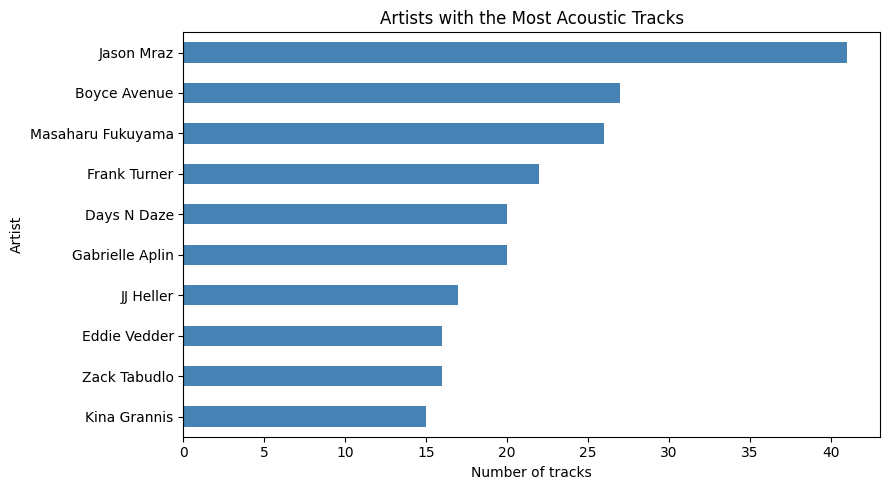

In [85]:
# Show the ten artists with the most acoustic tracks.
top_artists = df_acoustic['artists'].value_counts().head(10).sort_values()

plt.figure(figsize=(9, 5))
top_artists.plot(kind='barh', color='steelblue')
plt.title(f'Artists with the Most {GENRE.title()} Tracks')
plt.xlabel('Number of tracks')
plt.ylabel('Artist')
plt.tight_layout()
plt.show()

### Interpret the artist dominance chart

The chart shows that Jason Mraz has the most tracks in this genre, followed by Boyce Avenue and Masaharu Fukuyama. The top artists have more tracks than most other artists.

### Chart 2: Explore the popularity distribution in the genre

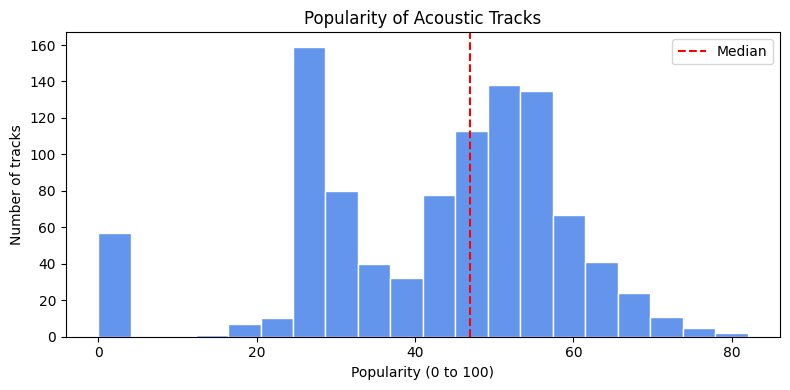

In [86]:
# Plot the popularity scores and mark the median.
plt.figure(figsize=(8, 4))
plt.hist(df_acoustic['popularity'], bins=20, color='cornflowerblue', edgecolor='white')
plt.axvline(df_acoustic['popularity'].median(), color='red', linestyle='--', label='Median')
plt.title(f'Popularity of {GENRE.title()} Tracks')
plt.xlabel('Popularity (0 to 100)')
plt.ylabel('Number of tracks')
plt.legend()
plt.tight_layout()
plt.show()

### Interpret the popularity histogram

Popularity scores vary widely. The median is 47 and the average is about 42, so many tracks have moderate popularity and a smaller number have very low scores.

### Chart 3: Analyse how musical features relate to each other

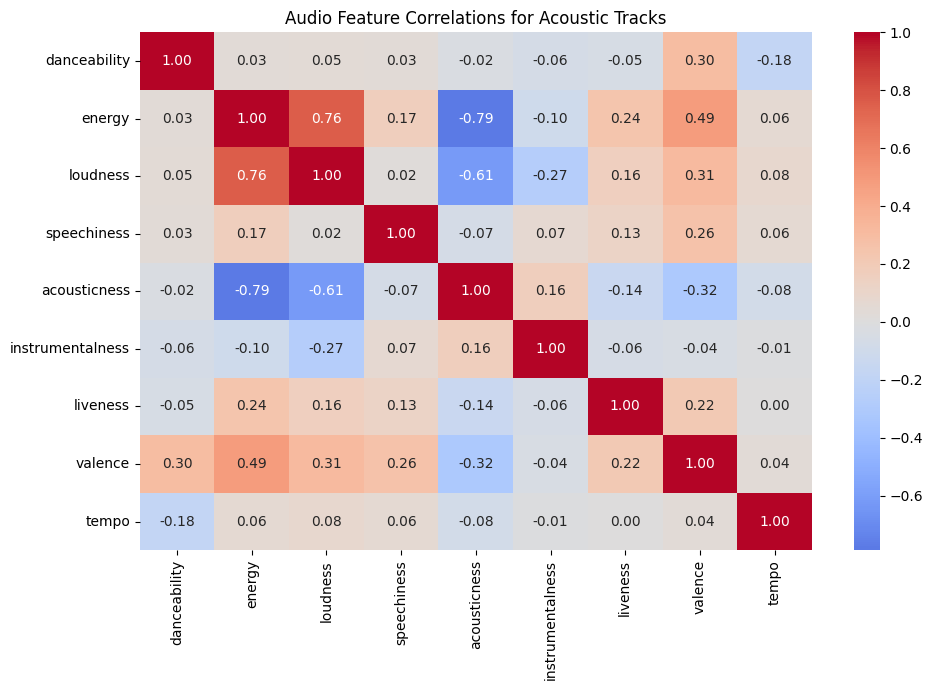

In [87]:
# Compare correlations between the main audio features.
audio_features = [
    'danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence', 'tempo'
]
feature_correlations = df_acoustic[audio_features].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(feature_correlations, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title(f'Audio Feature Correlations for {GENRE.title()} Tracks')
plt.tight_layout()
plt.show()

### Interpret the correlation heatmap

Acousticness and energy have a strong negative relationship (about -0.79). In this genre, tracks with higher acousticness usually have lower energy.

### Chart 4: Investigate one custom question about the genre

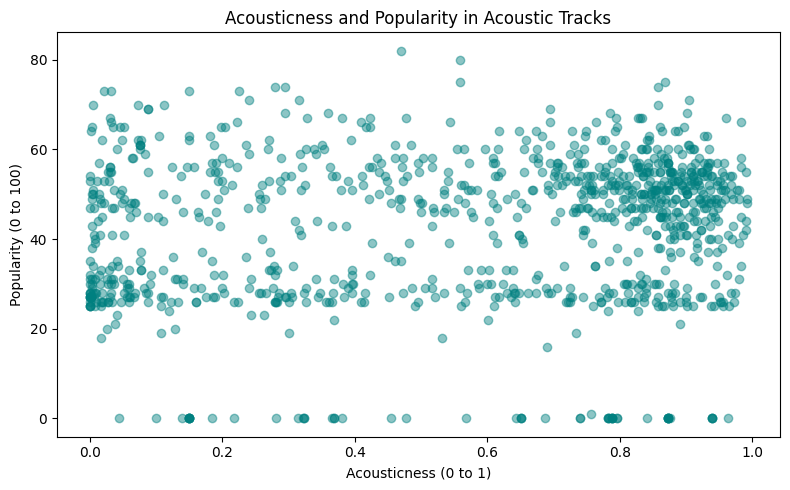

Correlation: 0.14


In [88]:
# Ask whether more acoustic tracks also tend to be more popular.
acousticness_popularity_corr = df_acoustic['acousticness'].corr(df_acoustic['popularity'])

plt.figure(figsize=(8, 5))
plt.scatter(df_acoustic['acousticness'], df_acoustic['popularity'], alpha=0.45, color='teal')
plt.title(f'Acousticness and Popularity in {GENRE.title()} Tracks')
plt.xlabel('Acousticness (0 to 1)')
plt.ylabel('Popularity (0 to 100)')
plt.tight_layout()
plt.show()
print(f'Correlation: {acousticness_popularity_corr:.2f}')

### Interpret the custom chart

The relationship is weak and positive (about 0.14). More acoustic tracks are only slightly more popular on average, so acousticness alone does not explain popularity.

### Exploration report ? 3 lines

1. Jason Mraz has the most tracks in the acoustic group, with 41 tracks.
2. The average popularity is about 42 and the median is 47.
3. Acousticness is strongly linked to lower energy, but only weakly linked to popularity.

## Part 4 ? Predict popularity

### 4.1 Choose the features and target variable for regression

In [89]:
# Predict popularity from audio and track features, not names or IDs.
features = [
    'danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_min',
    'explicit', 'mode', 'key', 'time_signature'
]
X = df_acoustic[features].copy()
X['explicit'] = X['explicit'].astype(int)  # Convert True/False to 1/0.
y = df_acoustic['popularity']

print('Input features:', features)
print('Target: popularity')

Input features: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_min', 'explicit', 'mode', 'key', 'time_signature']
Target: popularity


### 4.2 Split the data into training and testing sets

In [90]:
# Keep 20% of tracks aside for a fair test of the models.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print('Training tracks:', len(X_train))
print('Testing tracks:', len(X_test))

Training tracks: 800
Testing tracks: 200


### 4.3 Build the baseline linear regression model

In [91]:
# Fit a simple linear model as the baseline.
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)
print(f'Linear regression MAE: {linear_mae:.2f}')
print(f'Linear regression RMSE: {linear_rmse:.2f}')
print(f'Linear regression R-squared: {linear_r2:.3f}')

Linear regression MAE: 12.53
Linear regression RMSE: 16.17
Linear regression R-squared: -0.011


### 4.4 Interpret the model coefficients

In [92]:
# Show which features have the strongest positive or negative weights.
coefficients = pd.Series(linear_model.coef_, index=features)
coefficients = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index)
print('Largest linear model coefficients:')
print(coefficients.head(5).round(2))
print(f'Intercept: {linear_model.intercept_:.2f}')

Largest linear model coefficients:
speechiness    -14.33
danceability    13.48
valence        -13.07
explicit        -8.37
liveness         8.25
dtype: float64
Intercept: 32.50


### 4.5 Build the random forest regression model

In [93]:
# Try a random forest to capture patterns that a straight line may miss.
from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_predictions))
forest_r2 = r2_score(y_test, forest_predictions)
print(f'Random forest MAE: {forest_mae:.2f}')
print(f'Random forest RMSE: {forest_rmse:.2f}')
print(f'Random forest R-squared: {forest_r2:.3f}')

Random forest MAE: 11.78
Random forest RMSE: 15.37
Random forest R-squared: 0.087


### 4.6 Compare model performance and plot actual vs predicted popularity

            Model   MAE  RMSE  R-squared
Linear regression 12.53 16.17      -0.01
    Random forest 11.78 15.37       0.09


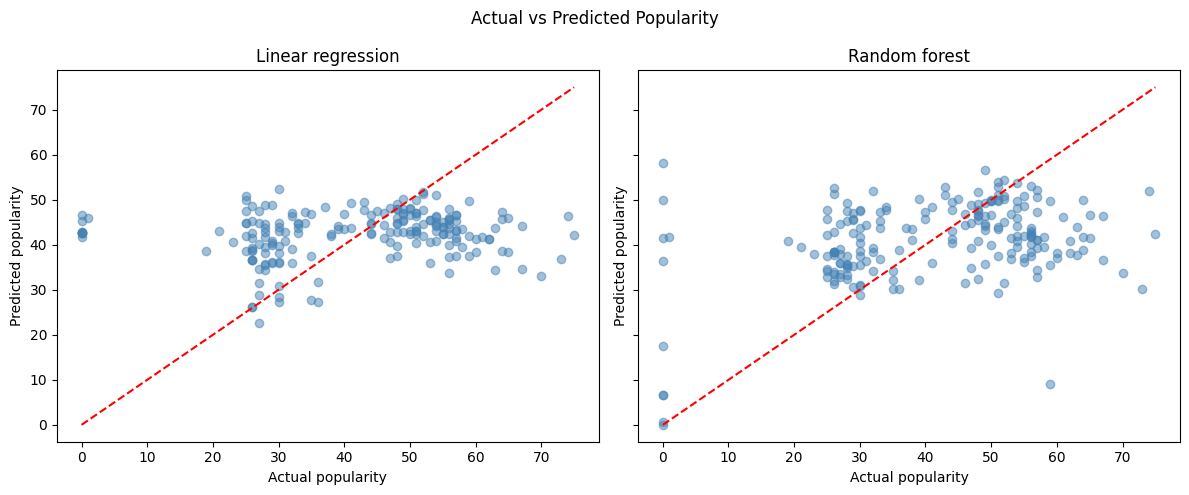

In [94]:
# Compare both models on the same test tracks.
model_scores = pd.DataFrame({
    'Model': ['Linear regression', 'Random forest'],
    'MAE': [linear_mae, forest_mae],
    'RMSE': [linear_rmse, forest_rmse],
    'R-squared': [linear_r2, forest_r2]
})
print(model_scores.round(2).to_string(index=False))

# Plot actual popularity against each model's predictions.
minimum = min(y_test.min(), linear_predictions.min(), forest_predictions.min())
maximum = max(y_test.max(), linear_predictions.max(), forest_predictions.max())
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for axis, predictions, title in zip(
    axes, [linear_predictions, forest_predictions], ['Linear regression', 'Random forest']
):
    axis.scatter(y_test, predictions, alpha=0.5, color='steelblue')
    axis.plot([minimum, maximum], [minimum, maximum], color='red', linestyle='--')
    axis.set_title(title)
    axis.set_xlabel('Actual popularity')
    axis.set_ylabel('Predicted popularity')
fig.suptitle('Actual vs Predicted Popularity')
fig.tight_layout()
plt.show()

### Write: Report on prediction results and real-world meaning

### Prediction report ? 3 lines

1. The random forest did better than linear regression: its test MAE was about 11.78, compared with 12.53.
2. The random forest R-squared was about 0.09, so audio features explain only a small part of popularity.
3. This means the streaming service should use audio features as one clue, alongside artist, playlist, and marketing information.

## Part 5 ? Spot the hits

### 5.1 Define the target variable without leaking popularity into the model

### 5.2 Split and scale the data for classification

### 5.3 Train logistic regression and decision tree models

### 5.4 Analyse the confusion matrix and compare errors

### Write: Interpret the classification results and business implication

## Part 6 ? Find the moods

### 6.1 Select the mood features and scale them for clustering

### 6.2 Choose the number of clusters using the elbow plot

### 6.3 Fit the K-means model and visualize the mood groups

### 6.4 Analyse the characteristics of each mood cluster

### Write: Name the mood groups and explain their meaning

## Part 7 ? Tune and finish

### 7.1 Try different model settings to improve performance

### 7.2 Compare the model before and after tuning

### Write: Explain whether tuning improved the model and why

## Part 8 ? Write it up

### Prepare the final report with summary, data description, charts, models, and recommendations

### Final review and submission checklist